In [5]:
import pandas as pd
import numpy as np

In [6]:
df = pd.read_csv(r"C:\Users\DELL\Desktop\OIBSIP\DataAnalytics-L1-EDARetailSales\retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [8]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values:
0


In [9]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [10]:
df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicate Rows:", df.duplicated().sum())

Shape After Removing Duplicates: (1000, 9)
Remaining Duplicate Rows: 0


In [11]:
print("Data Types Before Cleaning:")
print(df.dtypes)

Data Types Before Cleaning:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object


In [12]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date Data Type After Cleaning:")
print(df["Date"].dtype)

print("\nInvalid Dates:", df["Date"].isnull().sum())

Date Data Type After Cleaning:
datetime64[us]

Invalid Dates: 0


In [13]:
numeric_columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]

print("Numeric Columns Summary:")
print(df[numeric_columns].describe())

Numeric Columns Summary:
              Age     Quantity  Price per Unit  Total Amount
count  1000.00000  1000.000000     1000.000000   1000.000000
mean     41.39200     2.514000      179.890000    456.000000
std      13.68143     1.132734      189.681356    559.997632
min      18.00000     1.000000       25.000000     25.000000
25%      29.00000     1.000000       30.000000     60.000000
50%      42.00000     3.000000       50.000000    135.000000
75%      53.00000     4.000000      300.000000    900.000000
max      64.00000     4.000000      500.000000   2000.000000


In [14]:
print("Age below 0:", (df["Age"] < 0).sum())
print("Age above 100:", (df["Age"] > 100).sum())

print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price per Unit <= 0:", (df["Price per Unit"] <= 0).sum())
print("Total Amount < 0:", (df["Total Amount"] < 0).sum())

Age below 0: 0
Age above 100: 0
Quantity <= 0: 0
Price per Unit <= 0: 0
Total Amount < 0: 0


In [15]:
print("Missing Values After Date Conversion:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values After Date Conversion:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values:
0


In [16]:
# Remove rows where Date is missing or invalid
df = df.dropna(subset=["Date"])

# Fill missing numeric values with column median
numeric_columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with "Unknown"
categorical_columns = ["Gender", "Product Category", "Customer ID"]

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values After Cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values: 0


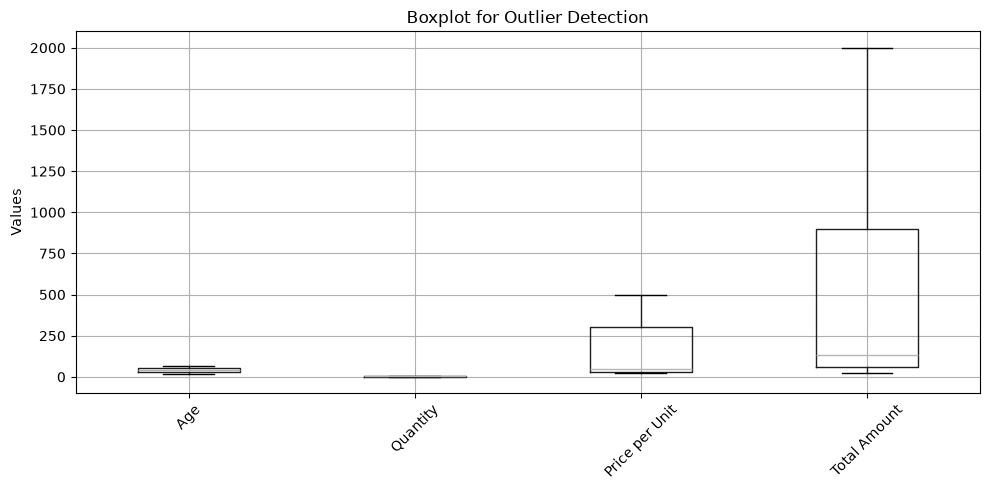

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
df[["Age", "Quantity", "Price per Unit", "Total Amount"]].boxplot()

plt.title("Boxplot for Outlier Detection")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
numeric_columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"{col}: {len(outliers)} potential outliers")

Age: 0 potential outliers
Quantity: 0 potential outliers
Price per Unit: 0 potential outliers
Total Amount: 0 potential outliers


In [20]:
print("Final Dataset Shape:", df.shape)

print("\nFinal Missing Values:")
print(df.isnull().sum())

print("\nFinal Duplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows of Cleaned Data:")
display(df.head())

Final Dataset Shape: (1000, 9)

Final Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Final Duplicate Rows: 0

First 5 Rows of Cleaned Data:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [21]:
output_path = "cleaned_retail_sales_dataset.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_path)

Cleaned dataset saved successfully!
File name: cleaned_retail_sales_dataset.csv


In [22]:
print("DATA CLEANING SUMMARY")
print("-" * 30)

print("Rows after cleaning:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nColumn Data Types:")
print(df.dtypes)

print("\nData cleaning completed successfully!")

DATA CLEANING SUMMARY
------------------------------
Rows after cleaning: 1000
Columns: 9
Missing values: 0
Duplicate rows: 0

Column Data Types:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Data cleaning completed successfully!
